# Food packaging

A snack factory packs a week of orders on three lines. Switching a line to another product means
stopping to clean it, and how long that takes depends on what ran before: oat bars after peanut bars
need a full allergen clean, while peanut bars after oat bars need much less. Two operators do all the
cleaning, and one person cannot clean two lines at once. The question is **which line packs which
order, and in what sequence**.

In this notebook you will:

1. describe a packing week as Python objects,
2. solve it and read the result as a line Gantt chart,
3. check the result yourself, including the score, without trusting the solver,
4. change the rules to forbid late orders and see what that costs,
5. lose a line and see what the plan gives up,
6. spend more search time on a result, one round after another,
7. fit a rush order into a week that has already started.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
from datetime import timedelta
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from optimaru import food_packaging as fp
from optimaru.food_packaging import constraints as rules
from optimaru.food_packaging.models import JobModel, PackagingScheduleModel, minute_to_datetime

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the week

All times are **integer minutes**, here counted from Monday 00:00.

| Object | What it holds |
| --- | --- |
| `Product` | one product. The cleaning time between any two products lives in a flat matrix on the schedule |
| `Operator` | one person who cleans lines |
| `Line` | one packing line: its start time and, once solved, its operator and job order |
| `Job` | one order: product, duration, `ideal_end_minute`, `max_end_minute` |
| `PackagingSchedule` | all of the above, and the score once solved |

`Job` also has `min_start_minute` and `priority`. **No rule reads them**: a job can start before its
minimum start, and priority changes nothing. Release dates or priorities would need your own constraint
in C++.

The week below is fictional. Seven products in three allergen families are ordered for delivery on
each of five days, so the same product comes back all week. The lines are close to full, which is what
makes the sequence matter: with spare capacity the solver would pack each product in one long run
ahead of time, and there would be almost nothing to clean.

In [2]:
HOUR = 60
DAY = 24 * HOUR
DAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
LINE_START = 6 * HOUR

FAMILY = {"Oat": "Plain", "Rice": "Plain", "Seed": "Plain", "Yogurt": "Dairy", "Choc": "Dairy",
          "Almond": "Nut", "Peanut": "Nut"}
PRODUCTS = list(FAMILY)
CLEAN_MINUTES = {
    ("Plain", "Plain"): 45, ("Plain", "Dairy"): 60, ("Plain", "Nut"): 60,
    ("Dairy", "Plain"): 150, ("Dairy", "Dairy"): 45, ("Dairy", "Nut"): 60,
    ("Nut", "Plain"): 240, ("Nut", "Dairy"): 240, ("Nut", "Nut"): 45,
}
cleanup = [0 if a == b else CLEAN_MINUTES[FAMILY[a], FAMILY[b]] for a in PRODUCTS for b in PRODUCTS]

rng = np.random.default_rng(5)
ORDERS = []
for due_day in range(1, 6):  # Tuesday to Saturday, 16:00
    ideal = due_day * DAY + 16 * HOUR
    for product in PRODUCTS:
        ORDERS.append((f"{product} {DAY_NAMES[due_day]}", product, int(rng.integers(9, 14)) * HOUR, ideal,
                       ideal + int(rng.integers(12, 30)) * HOUR))


def make_schedule(line_count=3, operator_count=2):
    """A fresh, unsolved week. Solvers work in place, so each experiment gets its own."""
    jobs = [fp.Job(name, name, PRODUCTS.index(product), duration, 0, ideal, latest)
            for name, product, duration, ideal, latest in ORDERS]
    return fp.PackagingSchedule(
        0, 7 * DAY, [fp.Product(p, p) for p in PRODUCTS], cleanup,
        [fp.Operator(f"Operator {k + 1}") for k in range(operator_count)],
        [fp.Line(f"L{k + 1}", f"Line {k + 1}", LINE_START) for k in range(line_count)],
        jobs,
    )


week = make_schedule()
total = sum(job.duration_minutes for job in week.jobs)
last_due = max(job.ideal_end_minute for job in week.jobs)
print(f"{len(week.jobs)} jobs, {len(week.lines)} lines, {len(week.operators)} operators")
print(f"{total / HOUR:.0f} hours of packing, against {len(week.lines) * (last_due - LINE_START) / HOUR:.0f} "
      f"line-hours before the last ideal end, before any cleaning")

35 jobs, 3 lines, 2 operators
376 hours of packing, against 390 line-hours before the last ideal end, before any cleaning


The cleaning matrix is not symmetric, so the order of two products matters, not only which products
share a line.

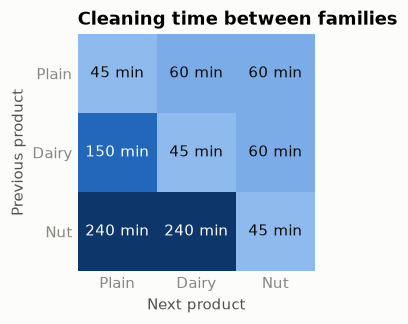

In [3]:
FAMILIES = ["Plain", "Dairy", "Nut"]
matrix = np.array([[CLEAN_MINUTES[a, b] for b in FAMILIES] for a in FAMILIES])

fig, ax = plt.subplots(figsize=(4.4, 2.8))
cmap = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#2a78d6", "#0d366b"])
ax.imshow(matrix, cmap=cmap, vmin=0, vmax=240)
for i, j in np.ndindex(matrix.shape):
    ax.text(j, i, f"{matrix[i, j]} min", ha="center", va="center", color="white" if matrix[i, j] > 120 else "#0b0b0b")
ax.set_xticks(range(3), FAMILIES)
ax.set_yticks(range(3), FAMILIES)
ax.tick_params(length=0)
ax.set(title="Cleaning time between families", xlabel="Next product", ylabel="Previous product")
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
plt.show()

## 2. Solve it

`fp.solve` works in place: job order, operators, start times and the score are written back. The score
has three levels, compared in order:

- **hard**: minutes past a job's `max_end_minute`, plus minutes of overlapping cleaning for lines that
  share an operator. `0` means the plan is feasible.
- **medium**: minus the minutes past each `ideal_end_minute`, and minus the production minutes of jobs
  left on no line. On this level, dropping a job costs its whole duration.
- **soft**: minus the square of each line's busy time, which spreads work evenly across the lines.

When a job cannot finish before its `max_end_minute`, the solver can leave it off every line
instead. That is why a dropped job is a real outcome here rather than a failure.

In [4]:
SOLVE = {"time_limit_seconds": 3.0, "random_seed": 42, "parallel_solver_count": 4}
fp.solve(week, **SOLVE)


def outcome(schedule):
    placed = [job for job in schedule.jobs if job.line_index >= 0]
    return {
        "late": [job for job in placed if job.end_minute > job.ideal_end_minute],
        "late_hours": sum(max(0, job.end_minute - job.ideal_end_minute) for job in placed) / HOUR,
        "dropped": [schedule.jobs[i] for i in schedule.unassigned_jobs],
        "dropped_hours": sum(schedule.jobs[i].duration_minutes for i in schedule.unassigned_jobs) / HOUR,
        "clean_hours": sum(job.start_production_minute - job.start_cleaning_minute for job in placed) / HOUR,
    }


result = outcome(week)
print("feasible:", week.score.is_feasible())
print("score   :", week.score.hard, "/", week.score.medium, "/", week.score.soft)
print(f"cleaning: {result['clean_hours']:.1f} hours")
print(f"late    : {len(result['late'])} jobs, {result['late_hours']:.1f} hours in total")
print("dropped :", [job.name for job in result["dropped"]])
print("operators per line:", [week.operators[line.operator_index].id for line in week.lines])

feasible: True
score   : 0 / -315 / -182842875
cleaning: 14.2 hours
late    : 3 jobs, 5.2 hours in total
dropped : []
operators per line: ['Operator 1', 'Operator 2', 'Operator 1']


### The week on the lines

Each row is a line, with blocks for production in the family color and cleaning in gray. The strip under
each line carries one mark per job on it: a triangle at the job's ideal end and a bar at its maximum
end. A red outline marks a job that ended after its ideal end.

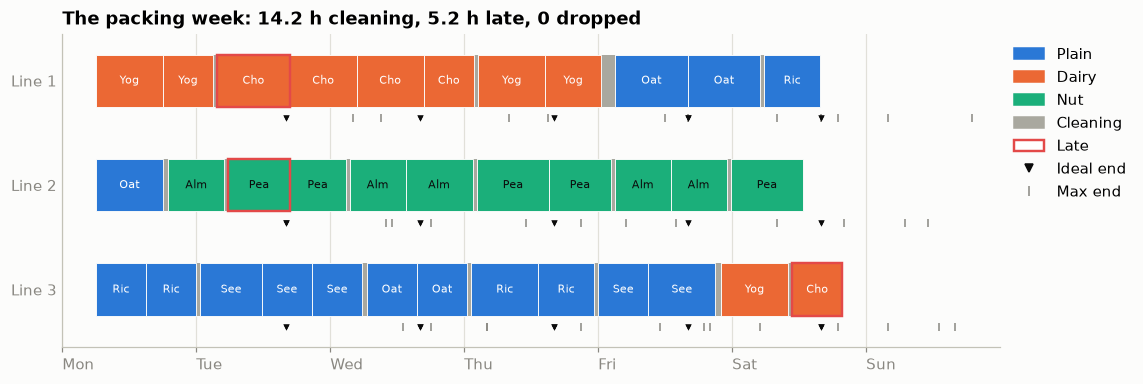

In [5]:
FAMILY_COLOR = {"Plain": COLORS[0], "Dairy": COLORS[1], "Nut": COLORS[2]}
CLEAN_COLOR = "#a9a89f"
LATE_COLOR = COLORS[7]
PRODUCT_NAMES = {i: p for i, p in enumerate(PRODUCTS)}


def format_days(ax, end=6 * DAY):
    ticks = np.arange(0, end + 1, DAY)
    ax.set_xticks(ticks / HOUR, [DAY_NAMES[int(t // DAY)] for t in ticks], ha="left")
    ax.grid(True, axis="x")
    ax.tick_params(axis="y", length=0)


def draw_gantt(ax, schedule, marks=True, highlight=()):
    jobs = schedule.jobs
    for row, line in enumerate(schedule.lines):
        for index in line.jobs:
            job = jobs[index]
            family = FAMILY[PRODUCT_NAMES[job.product_index]]
            ax.barh(row, (job.start_production_minute - job.start_cleaning_minute) / HOUR,
                    left=job.start_cleaning_minute / HOUR, height=0.5, color=CLEAN_COLOR)
            is_late = job.end_minute > job.ideal_end_minute
            ax.barh(row, job.duration_minutes / HOUR, left=job.start_production_minute / HOUR, height=0.5,
                    color=FAMILY_COLOR[family], edgecolor=LATE_COLOR if is_late else "#fcfcfb",
                    linewidth=1.6 if is_late else 0.6, zorder=3 if is_late else 2)
            ax.text((job.start_production_minute + job.duration_minutes / 2) / HOUR, row,
                    PRODUCT_NAMES[job.product_index][:3], ha="center", va="center", fontsize=7.5,
                    color="#0b0b0b" if family == "Nut" else "white", zorder=4)
            if job.id in highlight:
                ax.barh(row, job.duration_minutes / HOUR, left=job.start_production_minute / HOUR, height=0.5,
                        fill=False, edgecolor="#0b0b0b", linewidth=2, zorder=5)
            if marks:
                ax.scatter(job.ideal_end_minute / HOUR, row + 0.36, marker="v", s=16, color="#0b0b0b",
                           linewidth=0, zorder=4)
                ax.scatter(job.max_end_minute / HOUR, row + 0.36, marker="|", s=26, color=MUTED, linewidth=1, zorder=4)
    ax.set_yticks(range(len(schedule.lines)), [line.name for line in schedule.lines])
    ax.set_ylim(len(schedule.lines) - 0.45, -0.45)
    ax.set_xlim(0, 7 * DAY / HOUR)
    format_days(ax, 7 * DAY - 1)


GANTT_LEGEND = [
    *[Patch(color=FAMILY_COLOR[family], label=family) for family in FAMILY_COLOR],
    Patch(color=CLEAN_COLOR, label="Cleaning"),
    Patch(facecolor="white", edgecolor=LATE_COLOR, linewidth=1.6, label="Late"),
    Line2D([], [], marker="v", linestyle="", color="#0b0b0b", markersize=5, label="Ideal end"),
    Line2D([], [], marker="|", linestyle="", color=MUTED, markersize=7, label="Max end"),
]

fig, ax = plt.subplots(figsize=(11, 3.7))
draw_gantt(ax, week)
ax.set_title(f"The packing week: {result['clean_hours']:.1f} h cleaning, {result['late_hours']:.1f} h late, "
             f"{len(result['dropped'])} dropped")
ax.legend(handles=GANTT_LEGEND, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

Marks for several jobs often land on one spot, because orders share a delivery day. This second view has
one row per job, sorted by ideal end, so each deadline can be read on its own.

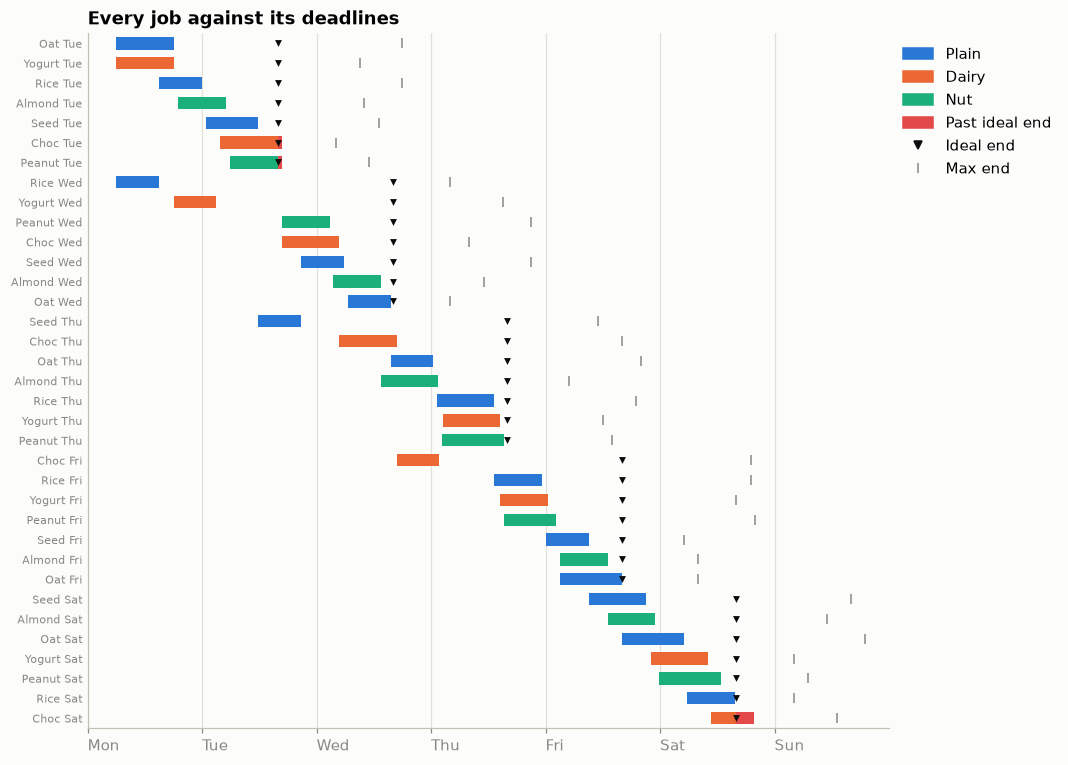

In [6]:
def draw_deadlines(schedule):
    placed = sorted((job for job in schedule.jobs if job.line_index >= 0),
                    key=lambda job: (job.ideal_end_minute, job.end_minute))
    fig, ax = plt.subplots(figsize=(9.4, 0.2 * len(placed) + 1.2))
    for row, job in enumerate(placed):
        family = FAMILY[PRODUCT_NAMES[job.product_index]]
        ax.barh(row, job.duration_minutes / HOUR, left=job.start_production_minute / HOUR, height=0.62,
                color=FAMILY_COLOR[family])
        ax.scatter(job.ideal_end_minute / HOUR, row, marker="v", s=20, color="#0b0b0b", linewidth=0, zorder=3)
        ax.scatter(job.max_end_minute / HOUR, row, marker="|", s=38, color=MUTED, linewidth=1, zorder=3)
        if job.end_minute > job.ideal_end_minute:
            ax.barh(row, (job.end_minute - job.ideal_end_minute) / HOUR, left=job.ideal_end_minute / HOUR,
                    height=0.62, color=LATE_COLOR, zorder=2)
    ax.set_yticks(range(len(placed)), [job.name for job in placed], fontsize=7.5)
    ax.set_ylim(len(placed) - 0.5, -0.5)
    ax.set_xlim(0, 7 * DAY / HOUR)
    format_days(ax, 7 * DAY - 1)
    handles = [*GANTT_LEGEND[:3], Patch(color=LATE_COLOR, label="Past ideal end"), *GANTT_LEGEND[5:]]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1, 1))
    ax.set_title("Every job against its deadlines")
    plt.show()


draw_deadlines(week)

## 3. Check the result yourself

A plan is fully described by each line's job order and operator. The check below rebuilds every time
from that order and the cleaning matrix, with no solver code, tests the hard rules, and recomputes all
three score levels.

In [7]:
def rebuild(schedule):
    """Walk each line in order. Returns (job index, line, clean start, production start, end) per job."""
    timeline = []
    for row, line in enumerate(schedule.lines):
        clock, previous = line.start_minute, None
        for index in line.jobs:
            job = schedule.jobs[index]
            clean = 0 if previous is None else schedule.cleanup_of(previous, job.product_index)
            start = clock + clean
            timeline.append((index, row, clock, start, start + job.duration_minutes))
            clock, previous = start + job.duration_minutes, job.product_index
    return timeline


def check_plan(schedule):
    timeline = rebuild(schedule)
    jobs, lines = schedule.jobs, schedule.lines
    placed = sorted(entry[0] for entry in timeline)
    past_max = sum(max(0, end - jobs[i].max_end_minute) for i, _, _, _, end in timeline)
    clash = 0
    for a, b in combinations(timeline, 2):
        same_operator = a[1] != b[1] and lines[a[1]].operator_index == lines[b[1]].operator_index
        if same_operator:
            clash += max(0, min(a[3], b[3]) - max(a[2], b[2]))
    late = sum(max(0, end - jobs[i].ideal_end_minute) for i, _, _, _, end in timeline)
    dropped = sum(jobs[i].duration_minutes for i in schedule.unassigned_jobs)
    busy = sum((max(e[4] for e in timeline if e[1] == row) - line.start_minute) ** 2
               for row, line in enumerate(lines) if line.jobs)
    return {
        "every job on one line or dropped": sorted(placed + list(schedule.unassigned_jobs)) == list(range(len(jobs))),
        "times match the solver": all(jobs[i].end_minute == end and jobs[i].start_cleaning_minute == clean
                                      for i, _, clean, _, end in timeline),
        "hard, recomputed": -(past_max + clash),
        "medium, recomputed": -(late + dropped),
        "soft, recomputed": -busy,
    }


for label, value in check_plan(week).items():
    print(f"{label}: {value}")
print(f"solver score: {week.score.hard} / {week.score.medium} / {week.score.soft}")

every job on one line or dropped: True
times match the solver: True
hard, recomputed: 0
medium, recomputed: -315
soft, recomputed: -182842875
solver score: 0 / -315 / -182842875


## 4. Change the rules, not the solver

`list_constraints()` shows what ships with this use case, and `constraints=` takes the list you want.
Only listed constraints are scored.

By default a late order costs one medium point per minute, and a dropped order costs one per minute
of its duration, so the solver prefers a few hours of lateness to losing a 10-hour order. Suppose a
customer contract forbids late delivery. Moving `ideal_end_date_time` to the hard level says that.

Weights need care here. The medium rules carry a weight of 10^10 in the engine, because medium is folded
into the engine's soft level, so a rule moved to hard needs `weight=1` to count plain minutes. `exponent`
shapes a cost, and `hard=False` on a medium rule folds it into soft and loses its meaning.

['max_end_date_time', 'ideal_end_date_time', 'minimize_makespan', 'operator_cleaning_conflict', 'maximize_jobs_assigned']


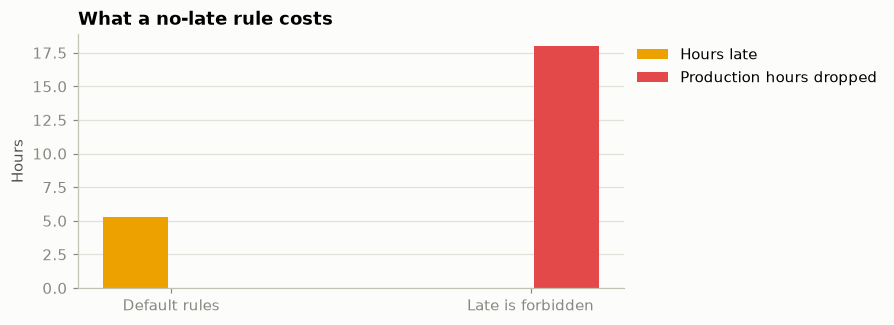

Default rules: 3 late, dropped []
Late is forbidden: 0 late, dropped ['Seed Wed', 'Rice Tue']


In [8]:
print(fp.list_constraints())

NEVER_LATE = [
    rules.max_end_date_time,
    rules.IdealEndDateTime(weight=1, hard=True),
    rules.minimize_makespan,
    rules.operator_cleaning_conflict,
    rules.maximize_jobs_assigned,
]
strict = make_schedule()
fp.solve(strict, constraints=NEVER_LATE, **SOLVE)
strict_result = outcome(strict)

labels = ["Default rules", "Late is forbidden"]
x = np.arange(2)
fig, ax = plt.subplots(figsize=(6.4, 3))
ax.bar(x - 0.1, [result["late_hours"], strict_result["late_hours"]], width=0.18, color=COLORS[3], label="Hours late")
ax.bar(x + 0.1, [result["dropped_hours"], strict_result["dropped_hours"]], width=0.18, color=COLORS[7],
       label="Production hours dropped")
ax.set_xticks(x, labels)
ax.set(title="What a no-late rule costs", ylabel="Hours")
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

for label, item in zip(labels, (result, strict_result)):
    print(f"{label}: {len(item['late'])} late, dropped {[job.name for job in item['dropped']]}")

The solver runs for a fixed time, so these numbers are the best found in that time rather than proven
optima. On a week this full a small difference between two runs can be search noise.

## 5. Lose a line

When a line goes down for the week, the same orders compete for less capacity, and the medium level
decides what gives way. A fourth line shows the other direction. The two operators stay the same.

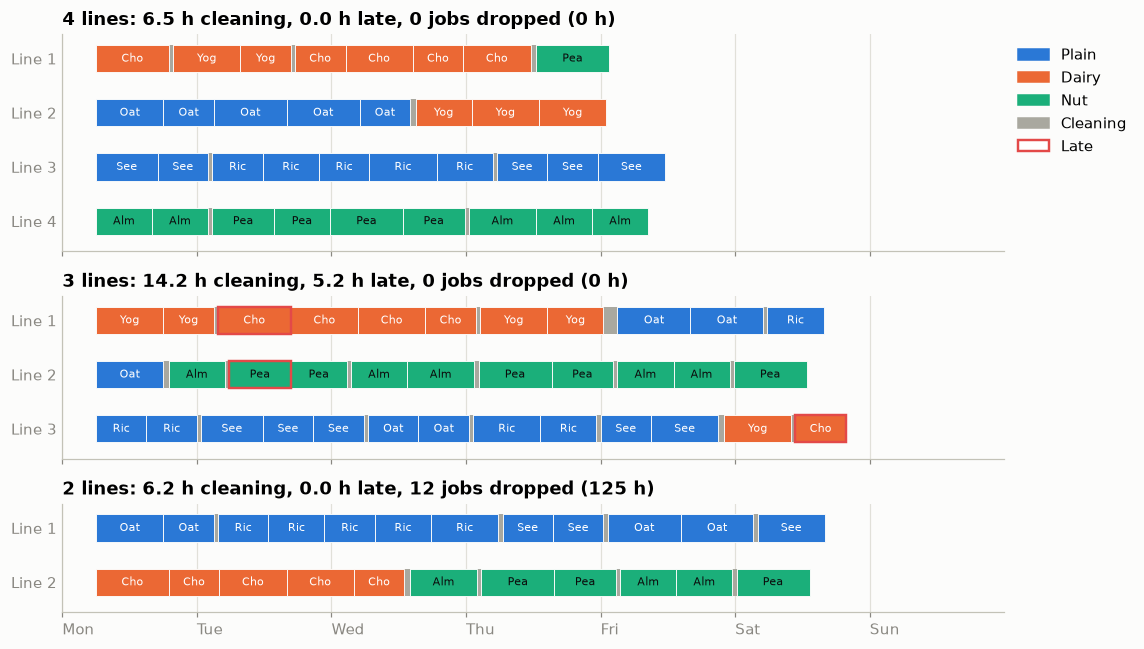

In [9]:
LINE_COUNTS = [4, 3, 2]
plans = {}
for count in LINE_COUNTS:
    plans[count] = make_schedule(line_count=count)
    fp.solve(plans[count], **SOLVE)

fig, axes = plt.subplots(3, 1, figsize=(10.5, 6), sharex=True, height_ratios=LINE_COUNTS)
for ax, count in zip(axes, LINE_COUNTS):
    item = outcome(plans[count])
    draw_gantt(ax, plans[count], marks=False)
    ax.set_title(f"{count} lines: {item['clean_hours']:.1f} h cleaning, {item['late_hours']:.1f} h late, "
                 f"{len(item['dropped'])} jobs dropped ({item['dropped_hours']:.0f} h)")
axes[0].legend(handles=GANTT_LEGEND[:5], loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
plt.show()

Cleaning depends on how many product changes a plan needs, so it can move either way as lines come and
go. A plan that drops jobs also skips their cleaning, so read the cleaning hours next to the dropped
hours.

## 6. Keep searching from an earlier result

The pydantic models in `optimaru.food_packaging.models` mirror the problem for JSON, and
`fp.with_initial_solution` turns an answer into the start of the next search.

Change `random_seed` between rounds. The same start with the same seed repeats the same search, so a
round that finds nothing leaves the next round with the identical input. Below, both versions spend the
same number of steps per round, and a step limit makes each round repeatable. The dotted line is the
best of several fresh solves that share nothing with the rounds. A line that stops well below it is
stuck, and a line that levels off at it has little left to find.

A new seed gives a round a chance, not a guarantee. This week has many deep local optima, so with other
round sizes the two lines can end level, and fresh solves can land on quite different scores.

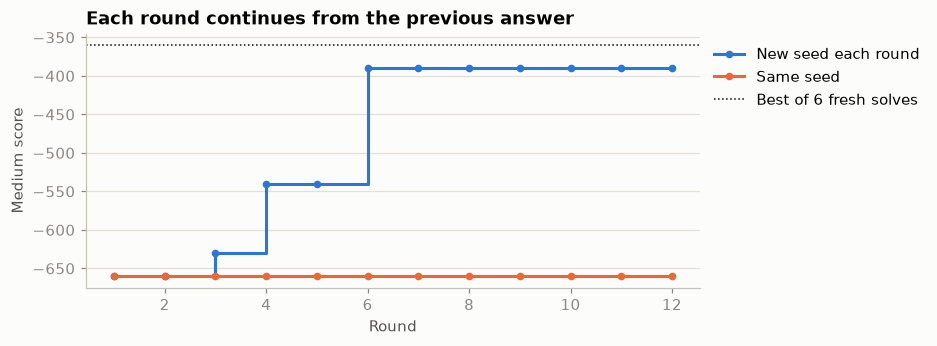

same seed: 11 of 11 rounds repeat the previous score, ends at (0, -660, -177877350)
new seed : 8 of 11 rounds repeat the previous score, ends at (0, -390, -183640950)
6 fresh solves, medium: -540 to -360


In [10]:
def run_rounds(rounds, new_seed, steps=50_000):
    problem = PackagingScheduleModel.from_core(make_schedule())
    solution, history = None, []
    for round_number in range(rounds):
        config = fp.SolverConfig()
        config.step_count_limit = steps
        start = problem if solution is None else fp.with_initial_solution(problem, solution)
        core = start.to_core()
        fp.solve(core, config=config, time_limit_seconds=30.0, random_seed=1 + round_number if new_seed else 1)
        solution = PackagingScheduleModel.from_core(core)
        history.append((solution.score_hard, solution.score_medium, solution.score_soft))
    return history


ROUNDS = 12
same_seed, new_seed = run_rounds(ROUNDS, False), run_rounds(ROUNDS, True)

fresh_scores = []
for seed in range(100, 106):
    fresh = make_schedule()
    fp.solve(fresh, time_limit_seconds=0.5, random_seed=seed)
    fresh_scores.append(fresh.score.medium)

fig, ax = plt.subplots(figsize=(7.2, 3))
for history, color, label in ((new_seed, COLORS[0], "New seed each round"), (same_seed, COLORS[1], "Same seed")):
    ax.plot(range(1, ROUNDS + 1), [score[1] for score in history], color=color, linewidth=2, marker="o",
            markersize=4, drawstyle="steps-post", label=label)
ax.axhline(max(fresh_scores), color="#0b0b0b", linewidth=1, linestyle=":", label="Best of 6 fresh solves")
ax.set(title="Each round continues from the previous answer", xlabel="Round", ylabel="Medium score")
ax.xaxis.get_major_locator().set_params(integer=True)
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

for label, history in (("same seed", same_seed), ("new seed ", new_seed)):
    repeats = sum(a == b for a, b in zip(history, history[1:]))
    print(f"{label}: {repeats} of {ROUNDS - 1} rounds repeat the previous score, ends at {history[-1]}")
print(f"6 fresh solves, medium: {min(fresh_scores)} to {max(fresh_scores)}")

## 7. A rush order mid-week

Wednesday, 06:00: a customer calls with a large rush order, due Thursday 16:00. Everything that has
started keeps running, and the rest of the week can change.

`pinned=True` keeps a job in place, and pinned jobs must form the start of a line's order. Here that
holds by construction, because the jobs that have started are the earliest on each line. Pinned jobs
still count in the score.

The new job has no place in the earlier solution. `with_initial_solution` keeps the old sequence as the
start, and construction places only the jobs in no line.

In [11]:
NOW = 2 * DAY + 6 * HOUR
plan = PackagingScheduleModel.from_core(week)
problem = PackagingScheduleModel.from_core(make_schedule())

started = []
for line, model_line in zip(week.lines, problem.lines):
    prefix = [week.jobs[i].id for i in line.jobs if week.jobs[i].start_cleaning_minute < NOW]
    model_line.job_ids = prefix
    started += prefix
for job in problem.jobs:
    job.pinned = job.id in started

problem.jobs.append(JobModel(
    id="RUSH", name="RUSH", product_id="Peanut", duration=timedelta(hours=14),
    min_start_time=minute_to_datetime(NOW),
    ideal_end_time=minute_to_datetime(3 * DAY + 16 * HOUR),
    max_end_time=minute_to_datetime(4 * DAY),
))
print(f"{len(started)} jobs pinned, {len(problem.jobs) - len(started)} still free, including the rush order")


def replan(start, seed=7):
    core = start.to_core()
    fp.solve(core, time_limit_seconds=1.5, random_seed=seed, parallel_solver_count=4)
    return core


replanned = replan(fp.with_initial_solution(problem, plan))
fresh_replan = replan(problem)


def line_of(schedule):
    return {schedule.jobs[i].id: line.id for line in schedule.lines for i in line.jobs}


before = line_of(week)
for label, schedule in (("warm start ", replanned), ("fresh start", fresh_replan)):
    item = outcome(schedule)
    now = line_of(schedule)
    moved = sum(now.get(job_id) != line for job_id, line in before.items() if job_id not in started)
    print(f"{label}: score {schedule.score.hard} / {schedule.score.medium} / {schedule.score.soft}, "
          f"{moved} of {len(before) - len(started)} free jobs off their line, "
          f"dropped {[job.name for job in item['dropped']]}, {item['late_hours']:.1f} h late")

early = [job.name for job in replanned.jobs if job.line_index >= 0 and not job.pinned
         and job.start_cleaning_minute < NOW]
print("free jobs that start before Wednesday 06:00:", early)

16 jobs pinned, 20 still free, including the rush order
warm start : score 0 / -1110 / -183759075, 1 of 19 free jobs off their line, dropped ['Peanut Thu'], 5.5 h late
fresh start: score 0 / -1110 / -183759075, 1 of 19 free jobs off their line, dropped ['Peanut Thu'], 5.5 h late
free jobs that start before Wednesday 06:00: []


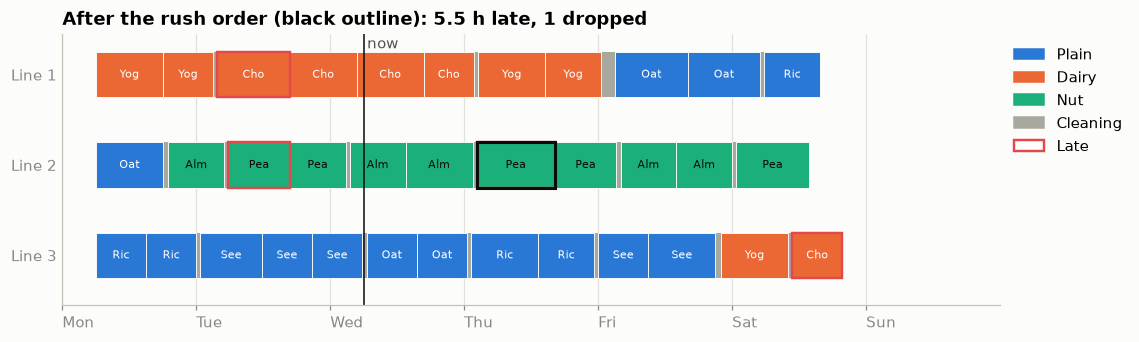

In [12]:
fig, ax = plt.subplots(figsize=(11, 3.2))
draw_gantt(ax, replanned, marks=False, highlight=("RUSH",))
ax.axvline(NOW / HOUR, color="#0b0b0b", linewidth=1)
ax.text(NOW / HOUR + 0.6, -0.42, "now", color=INK, va="top")
item = outcome(replanned)
ax.set_title(f"After the rush order (black outline): {item['late_hours']:.1f} h late, {len(item['dropped'])} dropped")
ax.legend(handles=GANTT_LEGEND[:5], loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

With much of the week settled the solver has little room, so a warm and a fresh start can end on the
same plan. Compare them in the printed output above rather than assuming the warm start helped.

## Next steps

- `use-cases/food-packaging/README.md` covers the solver configuration and how to add your own moves and
  constraints in C++, which is also where release dates or priorities would go.
- For a queue of work assigned to people rather than lines, see `task-assigning.ipynb`.